<div class="langswitch langswitch-ltr">
  <strong>English</strong> · <a href="#lang-fa">فارسی</a>
</div>

# Practical Issues: Starting Values and Choosing $K$

![](img/banner.png)

Computer Science Dept, Ferdowsi University of Mashhad

## Where this page sits

Section 14.3.11 of {cite}`hastie2009esl` (pp. 518-520) collects the two questions
that K-means and K-medoids cannot answer for themselves:

1. **where to start**, i.e. the initial set of centres $\{m_1,\dots,m_K\}$ or
   indices $\{i_1,\dots,i_K\}$;
2. **how many clusters**, when $K$ is not given by the problem.

The first is a local-minimum question, familiar from the
[families page](Three-Families-of-Clustering-Algorithms.ipynb). The second is
deeper, because the obvious tool - cross-validation - does **not** work here, and
the book is unusually explicit about why. What replaces it is a heuristic (the
kink) and its automation (the Gap statistic).

The [clustering validation page](Clustering-Validation-Metrics.ipynb) covers the
rest of the toolbox: purity and the other external measures, and the silhouette,
which answers the same question from inside a single clustering.

### What you should be able to do at the end

* describe forward stepwise initialisation and say what it buys over random
  starts;
* explain why cross-validation cannot select $K$ for clustering;
* derive the Gap statistic from the kink idea and state the rule (14.39);
* read a Gap plot, including the error bars.

## 1. Starting values

The book lists a range of practice, from "simple random selection" to a deliberate
**forward stepwise** strategy: choose the first centre, then the second to
minimise the criterion given the first, then the third given the first two, and so
on. Each step is a search over the observations, so the whole thing costs $K$
passes over the data, and it tends to spread the centres out - a new centre is
only chosen if it improves the fit, and a point inside an existing cluster
improves very little.

The experiment below compares the two strategies on data where it matters: three
groups that are close enough that some starts converge into the wrong
configuration.

In [1]:
import warnings

import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")

rng = np.random.default_rng(1)
# three elongated groups, close enough to be confused
X = np.vstack([
    rng.normal((-1.5, 0.0), (0.9, 2.2), size=(40, 2)),
    rng.normal((1.5, 0.0), (0.9, 2.2), size=(40, 2)),
    rng.normal((0.0, 3.0), (1.6, 0.6), size=(40, 2)),
])


def wcss(X, centres):
    """Sum of squared distances from each point to its nearest centre."""
    d = ((X[:, None, :] - centres[None, :, :]) ** 2).sum(-1)
    return d.min(axis=1).sum()


def forward_stepwise(X, K):
    """Choose centres one at a time, each minimising the criterion so far."""
    first = int(np.argmin(((X - X.mean(axis=0)) ** 2).sum(axis=1)))
    chosen = [first]
    while len(chosen) < K:
        best = None
        for cand in range(len(X)):
            if cand in chosen:
                continue
            trial = X[chosen + [cand]]
            value = wcss(X, trial)
            if best is None or value < best[0]:
                best = (value, cand)
        chosen.append(best[1])
    return X[chosen]


starts = []
for seed in range(50):
    km = KMeans(n_clusters=3, n_init=1, random_state=seed).fit(X)
    starts.append(km.inertia_)
starts = np.array(starts)

centres = forward_stepwise(X, 3)
km_fs = KMeans(n_clusters=3, init=centres, n_init=1, random_state=0).fit(X)

print(f"random starts (50 runs): best {starts.min():8.1f}  "
      f"median {np.median(starts):8.1f}  worst {starts.max():8.1f}")
print(f"runs above the median  : {(starts > np.median(starts)).sum()} of 50")
print(f"forward stepwise       : {km_fs.inertia_:8.1f}")

random starts (50 runs): best    320.8  median    323.7  worst    380.6
runs above the median  : 25 of 50
forward stepwise       :    325.3


The forward stepwise start lands within a few units of the best value the fifty
random starts found, and far from the worst, in a single attempt. On well-separated
data every strategy gives the same answer and none of this matters; the distance
between best and worst above is the cost of not choosing.

## 2. Choosing $K$: the kink, and why cross-validation fails

The data-based approach is to compute the within-cluster dissimilarity $W_K$ for
$K = 1, 2, \dots, K_{\max}$ and look at the curve. It always decreases. The
reason is not that more clusters fit better in a statistical sense, and the book
is precise: **even on an independent test set** the criterion decreases, because
"a large number of cluster centers will tend to fill the feature space densely and
thus will be close to all data points". There is no test-set penalty to pay, so
the usual machine-learning remedy of holding data out does not select $K$ at all.
The cell below shows it happening.

In [2]:
from sklearn.model_selection import train_test_split

X_tr, X_te = train_test_split(X, test_size=0.4, random_state=0)
print(f"{'K':>2} {'W_K on the held-out data':>28}")
for K in range(1, 9):
    km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X_tr)
    print(f"{K:>2} {wcss(X_te, km.cluster_centers_):26.1f}")

 K     W_K on the held-out data
 1                      321.9
 2                      177.6
 3                      124.8
 4                       85.9
 5                       69.9
 6                       61.3
 7                       57.0
 8                       44.9


Monotone decreasing from top to bottom, so the minimum is always $K = K_{\max}$.
Clustering is not prediction: there is nothing to predict, and no held-out error
to pay for overfitting.

What the book uses instead is the shape of the curve. If the data really contain
$\bar K$ groups, then for $K < \bar K$ the algorithm must merge groups that are far
apart, and each extra cluster reduces $W$ a lot; for $K > \bar K$ the extra cluster
splits a group that is already tight, and the reduction is small. So the
*successive differences* $W_K - W_{K+1}$ drop sharply at $\bar K$, which is the
"kink" - and it is a heuristic. The
[tumour example](Tumor-Microarray-Example.md) is the honest counterexample: the
curve there has no kink at all, and the book chooses $K = 3$ for illustration.

## 3. The Gap statistic

The Gap statistic replaces the visual kink with a reference curve. For each $K$
compare the observed $\log W_K$ with the value expected if the data had **no
clusters at all**, obtained by sampling uniform data over the box that contains
the data:

$$
G(K) = \frac{1}{B}\sum_{b=1}^{B} \log W_K^{(b)} - \log W_K ,
$$

where $W_K^{(b)}$ is computed on the $b$-th uniform sample. If the data are one
blob, the two curves are close and $G(K)$ stays near zero. If there are $\bar K$
groups, the observed curve falls faster than the reference up to $\bar K$ and then
runs parallel to it, so the gap peaks and then flattens.

The error bar accounts for the simulation, with $s_K$ the standard deviation of
$\log W_K$ over the $B$ samples:

$$
s'_K = s_K \sqrt{1 + 1/B},
\qquad
\hat K = \arg\min \left\{ K : G(K) \ge G(K+1) - s'_{K+1} \right\}.
\qquad \text{(14.39)}
$$

The rule is not "take the maximum": it takes the **smallest** $K$ whose gap is
within one error bar of the next one, which is the formal version of "stop when
the curve flattens". And it works when the data have a single cluster - then
$\hat K = 1$ - which is the case where the kink method has nothing to point at.

In [3]:
def gap_statistic(X, Ks, B=20, seed=0):
    """Observed and uniform-reference log W_K, the gap, and the error bars."""
    rng = np.random.default_rng(seed)
    lo, hi = X.min(axis=0), X.max(axis=0)
    logW_obs, logW_ref, sd_ref = [], [], []
    for K in Ks:
        km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X)
        logW_obs.append(np.log(wcss(X, km.cluster_centers_)))
        ref = []
        for _ in range(B):
            uniform = rng.uniform(lo, hi, size=X.shape)
            kmr = KMeans(n_clusters=K, n_init=3, random_state=0).fit(uniform)
            ref.append(np.log(wcss(uniform, kmr.cluster_centers_)))
        logW_ref.append(np.mean(ref))
        sd_ref.append(np.std(ref))
    logW_obs = np.array(logW_obs)
    logW_ref = np.array(logW_ref)
    gap = logW_ref - logW_obs
    sk = np.array(sd_ref) * np.sqrt(1 + 1 / B)
    return logW_obs, logW_ref, gap, sk


# a data set whose answer is known: three well-separated groups of 30 points
rng_g = np.random.default_rng(7)
Xg = np.vstack([rng_g.normal(c, 0.35, size=(30, 2))
                for c in [(-4.0, 0.0), (4.0, 0.0), (0.0, 6.0)]])

Ks = np.arange(1, 9)
logW_obs, logW_ref, gap, sk = gap_statistic(Xg, Ks, B=20)
logW_obs = logW_obs - logW_obs[0]   # both curves shifted to zero at one cluster
logW_ref = logW_ref - logW_ref[0]

for K, g, s in zip(Ks, gap, sk):
    print(f"K = {K}:  gap = {g:6.3f}   error bar = {s:5.3f}")

K_hat = Ks[-1]                      # smallest K within one error bar of K + 1
for i in range(len(Ks) - 1):
    if gap[i] >= gap[i + 1] - sk[i + 1]:
        K_hat = Ks[i]
        break
print("\nGap estimate of K:", K_hat)

K = 1:  gap = -0.506   error bar = 0.083
K = 2:  gap = -0.385   error bar = 0.083
K = 3:  gap =  3.028   error bar = 0.078
K = 4:  gap =  2.865   error bar = 0.053
K = 5:  gap =  2.795   error bar = 0.069
K = 6:  gap =  2.782   error bar = 0.079
K = 7:  gap =  2.802   error bar = 0.073
K = 8:  gap =  2.833   error bar = 0.058

Gap estimate of K: 3


The printed estimate is the smallest $K$ whose gap is within one error bar of the
following gap, and here it is the number of groups the data were built from. Note
the shape. For $K = 1$ and $K = 2$ the gap is *negative*: the observed data are
three tight groups spread over a large box, while the reference is one diffuse
blob, so one or two centres describe the reference better than they describe the
data. At $K = 3$ the observed curve collapses and the gap jumps by more than three
units - the kink, measured against a reference instead of guessed by eye. After
that the two curves run parallel and the gap is flat.

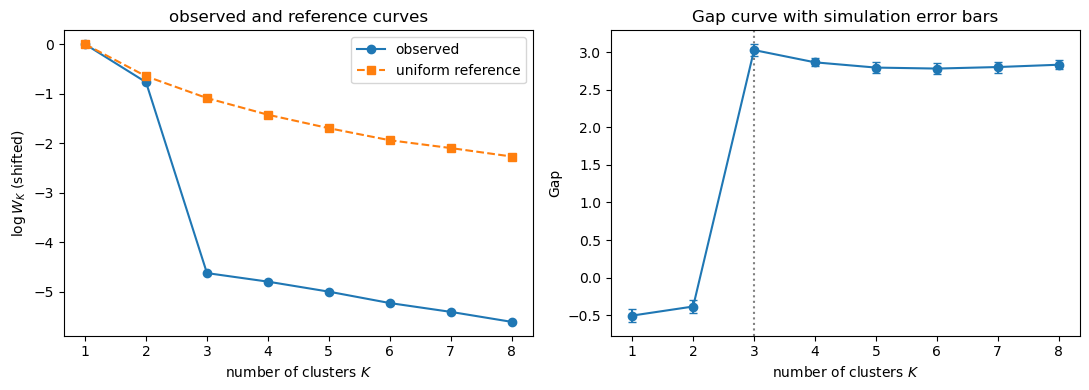

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(Ks, logW_obs, "o-", label="observed")
axes[0].plot(Ks, logW_ref, "s--", label="uniform reference")
axes[0].set_xlabel("number of clusters $K$")
axes[0].set_ylabel(r"$\log W_K$ (shifted)")
axes[0].set_title("observed and reference curves")
axes[0].legend()

axes[1].errorbar(Ks, gap, yerr=sk, fmt="o-", capsize=3)
axes[1].axvline(K_hat, color="grey", linestyle=":")
axes[1].set_xlabel("number of clusters $K$")
axes[1].set_ylabel("Gap")
axes[1].set_title("Gap curve with simulation error bars")
plt.tight_layout()
plt.show()

## 4. What to report

Neither criterion is a test. Both are heuristics that answer "how many groups would
a reasonable person see in this picture", and the honest way to use them is:

* report the whole $W_K$ curve, not only the chosen $K$;
* say which rule chose $K$ - the problem (a company with $K$ sales people), the
  kink, the Gap statistic, or a validation measure;
* check stability: recluster bootstrap samples and see whether the same groups come
  back;
* remember that the number of starts and the number of clusters are both part of
  the answer, as the first section shows.

## Summary

* Initialisation is a choice: random starts need repetition, forward stepwise
  chooses centres one at a time to minimise the criterion and usually lands near
  the best solution found by many random starts.
* $W_K$ decreases monotonically **even on held-out data**, because centres fill the
  feature space; cross-validation therefore cannot select $K$.
* The kink in $W_K$, or in $\log W_K$, is the heuristic answer, and it can be
  absent - as in the tumour example.
* The Gap statistic compares $\log W_K$ with a uniform reference, and (14.39) picks
  the smallest $K$ within one error bar of the next; it also returns one cluster
  when that is the right answer.
* Whatever rule you use, report the curve and the rule.

## Exercises

1. Run 200 random starts on the data of Section 1 and plot the histogram of final
   values. How many distinct local minima are there?
2. Implement the kink rule as code: the first $K$ where $W_K - W_{K+1}$ falls below
   a fraction of the previous difference. How sensitive is the answer to that
   fraction?
3. Apply the Gap statistic to the data of the
   [tumour example](Tumor-Microarray-Example.md) (or to 64 points drawn from
   three overlapping Gaussians) and see whether it finds a kink that the curve
   does not show.
4. Repeat the Gap computation with $B = 5$ and $B = 100$. What happens to the
   error bars, and to $\hat K$?
5. Show by simulation that the Gap statistic returns $\hat K = 1$ for data from a
   single Gaussian, and that the kink rule does not.
6. Forward stepwise chooses centres to minimise $W$; K-means++ samples them with
   probability proportional to the squared distance to the nearest chosen centre.
   Compare the two on 100 starts.

## Sources

* Forward stepwise initialisation, the argument against cross-validation, the
  kink, the Gap statistic, (14.39) and Figure 14.11: §14.3.11 of
  {cite}`hastie2009esl`, pp. 518-520; the Gap statistic is Tibshirani, Walther and
  Hastie (2001), cited there.
* The absent kink on real data: [Tumor-Microarray-Example](Tumor-Microarray-Example.md)
  and ESL Figure 14.8.
* Other ways to judge a clustering - purity, Rand, Jaccard, silhouette:
  [Clustering-Validation-Metrics](Clustering-Validation-Metrics.ipynb).